### Importando Bibliotecas e Lendo Arquivo

In [105]:
import numpy as np
import matplotlib.pyplot as plt
import os
from numpy.fft import fft, fftshift, fftfreq  # bibliotecas usadas para cálculo numérico, gráficos e operações de ficheiro/FFT.

# Ajustar os gráficos no notebook
%matplotlib inline
plt.rcParams.update({
    'figure.figsize': (12, 4),
    'axes.grid': True
})  

filename = '../ds2.bin'  # diretório do arquivo .bin
fs = 25_000_000          # taxa de amostragem
bytes_per_sample = 4     # 2 bytes I (parte real) + 2 bytes Q (parte imaginária) (int16)

# Configurando o tempo da Janela de Observação
t_start = 60.0
t_end   = 300.0  # Mesmo intervalo do codev2 para comparação correta
# n_pontos = 1000 # numeros de amostras

# cria o espaço entre amostras
# tempos_simples = np.linspace(t_start, t_end, n_pontos)

# Lendo informações sobre o arquivo
total_bytes = os.path.getsize(filename) # tamanho do arquivo em bytes
N_int16 = total_bytes // 2              # quantidade de int16 no arquivo (cada int16 são 2 bytes)
N_samples = total_bytes // bytes_per_sample  # num de amostras complecas (I,Q) cada uma tem 4 bytes
print(f'Arquivo: {filename}\n- Tamanho: {total_bytes:,} bytes\n- Amostras complexas: {N_samples:,}\n- Duração aprox: {N_samples/fs:.2f} s')

# abre o arquino na mem mapeada sem carregar tudo na RAM (lê fatias)
mm = np.memmap(filename, dtype=np.int16, mode='r', shape=(N_int16,))

# Função para extrair uma janela em um determinado tempo
def read_window_at_time(t_sec: float, win_N: int) -> np.ndarray:
    #t_sec é o tempo em seg no centro da janela
    ctr = int(t_sec * fs) # índice da amostra central da janela de win_N amostras
    half = win_N // 2
    start = max(0, ctr - half) # max(0,...) evita amostras com indices negativos (nao existem no dataset)
    end = min(N_samples, start + win_N) 
    # garantir comprimento exato quando estamos próximos das bordas do arquivo
    start = max(0, end - win_N) # garantir que a janela vai ter o num certo de amostras
    i0 = 2 * start 
    i1 = 2 * end
    seg = mm[i0:i1]
    I = seg[0::2].astype(np.float32) # pega todos os componentes pares
    Q = seg[1::2].astype(np.float32) # pega todos os componentes impares
    return I + 1j * Q # vetor completo (float32) com win_N amostras (talvez menos perto das bordas)


Arquivo: ../ds2.bin
- Tamanho: 45,717,913,600 bytes
- Amostras complexas: 11,429,478,400
- Duração aprox: 457.18 s


### Análise da Potência 

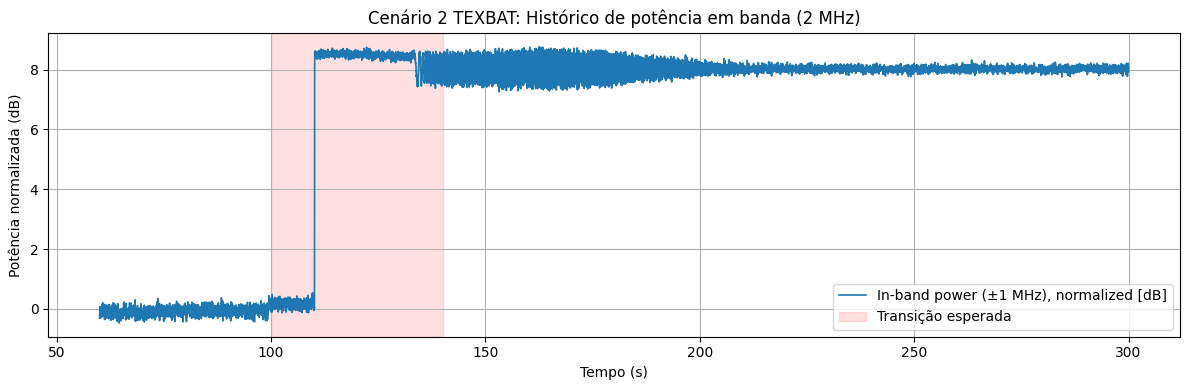

Delta dB (pós - pré): 8.027959503930937 dB


In [106]:
# Potência in‑band (~±1 MHz ao redor de DC)
def inband_power_2mhz(x: np.ndarray) -> tuple[float, float]:
    N = len(x) # tamanho do array de amostras complexas
    # Janela Hann para reduzir vazamento espectral // pega um trecho finito do sinal
    w = np.hanning(N).astype(np.float32) # suaviza bordas
    X = fftshift(fft(x * w)) # calcula a tansformada de fourier para o trecho da janela 
    freqs = fftshift(fftfreq(N, d=1/fs))  # Transformar para frequencia
    mask = np.abs(freqs) <= 1_000_000.0  # ±1 MHz
    # PSD aproximada: |X|^2; integra apenas os bins selecionados e normaliza pela energia da janela
    p_lin = float(np.sum(np.abs(X[mask])**2) / np.sum(w**2)) # potencia linear
    p_db = 10.0 * np.log10(p_lin + 1e-20) # potencia em db
    return p_lin, p_db

n_points = 10000 # num de centros (ctr) de janelas
win_N = 32768  # tam da janela -> 2^15 ≈ 1.31 ms a 25 Msps 
T = np.linspace(t_start, t_end, n_points) # array com o ctr de cada janela [n_points]


power_lin = np.empty(n_points, dtype=np.float64)
power_db = np.empty(n_points, dtype=np.float64)


# para cada tempo, ler janela e estimar potência em banda (±1 MHz)
for i, t in enumerate(T):
    # read_window_at_time: lê win_N amostras complexas centradas em 't' (I + 1j*Q)
    x = read_window_at_time(float(t), win_N)
    # inband_power_2mhz: aplica Hann+FFT e integra |X|^2 apenas nos bins |f| <= 1 MHz
    p_lin, p_db = inband_power_2mhz(x)
    # Armazenar resultados (potência linear e dB) para uso posterior
    power_lin[i] = p_lin
    power_db[i] = p_db

# Normalizar potência ao nível pré-ataque
pre_mask = T < 120.0  # janela considerada 'antes do ataque'
# Calcula a mediana das potências pré‑ataque como nível de referência 
baseline = np.median(power_lin[pre_mask]) if np.any(pre_mask) else np.median(power_lin)
# Converter razão linear -> dB para visualização (adiciona pequena constante para estabilidade numérica)
power_norm_db = 10.0 * np.log10((power_lin / (baseline + 1e-30)) + 1e-30)

# Plot: potência normalizada ao longo do tempo
fig, ax = plt.subplots(1, 1, figsize=(12, 4))
ax.plot(T, power_norm_db, '-', lw=1.2, label='In-band power (±1 MHz), normalized [dB]')
# Marca a janela esperada de transição (120–140 s) para referência visual
ax.axvspan(100, 140, color='r', alpha=0.12, label='Transição esperada')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('Potência normalizada (dB)')
ax.set_title('Cenário 2 TEXBAT: Histórico de potência em banda (2 MHz)')
ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

# Estatística rápida: diferença de mediana pós- vs pré-janela de transição (indicador de overpower)
print('Delta dB (pós - pré):', float(np.median(power_norm_db[T>140]) - np.median(power_norm_db[T<120])), 'dB')

### Análise C/N0 

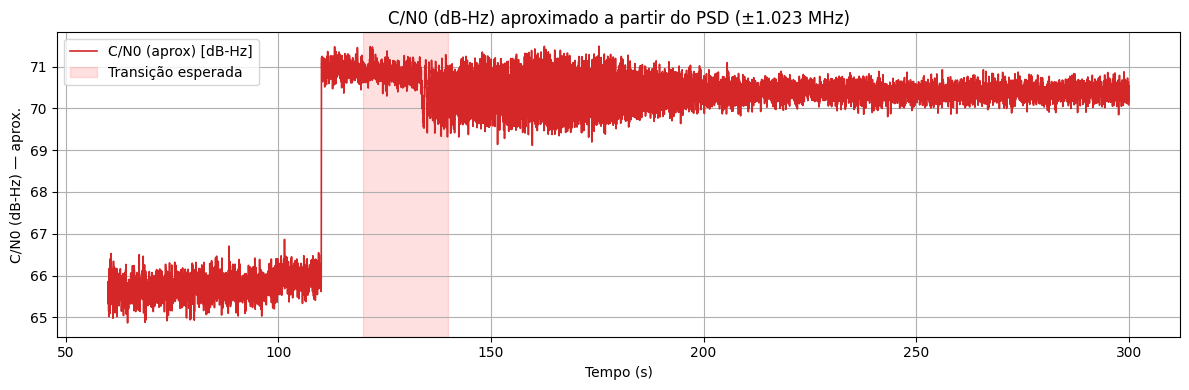

C/N0 pré (mediana, t<120s):  65.83380530671366 dB-Hz
C/N0 pós (mediana, t>140s):  70.40139578177636 dB-Hz
Δ (pós - pré):  4.567590475062701 dB-Hz


In [107]:
# C/N0 (dB-Hz) — estimativa por PSD (sem despreading) - aproximação de tendência (não absoluta), baseada em:
# - Centro espectral (fc) por centróide em ±2 MHz
# - N0 estimado nas bandas de ruído: 1.5–3.5 MHz (ambos os lados)

# - Banda do sinal: ±1.023 MHz
# C é a potência do sinal (portadora) integrada na banda do sinal
# - N0 é a densidade espectral de ruído
# Fórmula: C/N0 ≈ (P_band - N0 * B_sig) / N0  [Hz]  → 10*log10(·) em dB-Hz

# Esperamos ver C/N0 tendo aumento após o spoofing pois esperamos que C aumente pois acontece um overpower

win_N_cn0 = 32768  # mesmo tamanho de janela
B_sig = 2 * 1.023e6 # largura ocupada pelo sinal C/A

def estimate_cn0_dbhz(x: np.ndarray) -> float:
    N = len(x)
    w = np.hanning(N).astype(np.float32) # reduzir o vazamento espectral
    X = fftshift(fft(x * w))             # transformada de fourier na janela e produz X[k]
                                         # X[k] (amplitude e fase) e desloca DC para o centro do vetor
    f = fftshift(fftfreq(N, d=1/fs)) # gera valores de frequencia correspondentes a cada bin  e reordena colocando 0 Hz centro

    """"
    Entao ... o sinal de gps ocupa +- 1MHz só que para evitar que o deslocamento do efeito doppler interfira na faixa que estamos lendo, centralizamos a frequencia da amostra antes de realizar os calculos
    """

    # Periodograma (dois lados) por Hz
    S = (np.abs(X)**2) / (fs * np.sum(w**2)) # potência (|X|^2) normalizada para obter densidade por Hz
    df = f[1] - f[0] # espaçamento em frequencia entre bins

    # Estimar fc pelo centróide em ±2 MHz
    band2 = np.abs(f) <= 2.0e6  # mascara, para selecionar bins dentro de +- 2MHz (estamos usando uma faixa maior para garantir que o centro real caiba na região de busca.)
    S2 = S[band2] # PSD restrita a regiao de +- 2MHz
    f2 = f[band2] # frequencia dos bins selecionados
    denom = np.sum(S2) + 1e-30 
    fc = float(np.sum(f2 * S2) / denom) # centroide espectral - frequencia central (media ponderadas fas frequencias) 


    # Máscaras de banda do sinal e bandas de ruído
    sig_mask = np.abs(f - fc) <= 1.023e6
    noise_mask = (np.abs(f - fc) >= 1.5e6) & (np.abs(f - fc) <= 3.5e6) # bandas laterais afastadas para estimar ruído

    # N0 por mediana
    if not np.any(noise_mask):
        return np.nan
    N0 = float(np.median(S[noise_mask]))

    # Potência integrada na banda do sinal
    P_band = float(np.sum(S[sig_mask]) * df)

    # C estimado (subtrai a contribuição do ruído) e C/N0
    C_est = max(P_band - N0 * B_sig, 1e-30)
    CNo = C_est / (N0 + 1e-30)  # Hz
    return 10.0 * np.log10(CNo)


CNo_dbHz = np.empty_like(T)
for i, t in enumerate(T):
    x = read_window_at_time(float(t), win_N_cn0)
    CNo_dbHz[i] = estimate_cn0_dbhz(x)

fig, ax = plt.subplots(1,1, figsize=(12,4))
ax.plot(T, CNo_dbHz, '-', lw=1.2, color='C3', label='C/N0 (aprox) [dB-Hz]')
ax.axvspan(120, 140, color='r', alpha=0.12, label='Transição esperada')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('C/N0 (dB-Hz) — aprox.')
ax.set_title('C/N0 (dB-Hz) aproximado a partir do PSD (±1.023 MHz)')
ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

print('C/N0 pré (mediana, t<120s): ', float(np.nanmedian(CNo_dbHz[T<120])), 'dB-Hz')
print('C/N0 pós (mediana, t>140s): ', float(np.nanmedian(CNo_dbHz[T>140])), 'dB-Hz')
print('Δ (pós - pré): ', float(np.nanmedian(CNo_dbHz[T>140]) - np.nanmedian(CNo_dbHz[T<120])), 'dB-Hz')

### Deslocamento de frequência (Doppler)

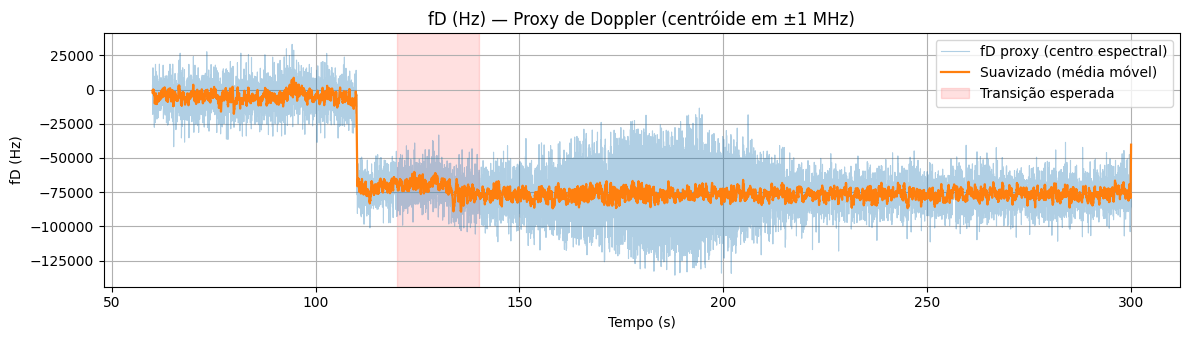

fD pré (mediana, t<120s):  -7951.817904793463 Hz
fD pós (mediana, t>140s):  -76549.47059604974 Hz
Δ fD (pós - pré):  -68597.65269125627 Hz


In [108]:
def doppler_proxy_centroid(x: np.ndarray) -> float:
    N = len(x)
    w = np.hanning(N).astype(np.float32)
    X = fftshift(fft(x * w))
    freqs = fftshift(fftfreq(N, d=1/fs))
    mask = np.abs(freqs) <= 1_000_000.0
    P = (np.abs(X)**2)[mask] # tem a energia por dos bins selecionados
    F = freqs[mask] # Frequências associadas aos bins selecionados (apenas as que estão dentro de ±1 MHz).
    denom = float(np.sum(P)) + 1e-30 # soma das potências em P (energia total dentro da banda)
    return float(np.sum(F * P) / denom) # retorna média ponderada das frequências `F` usando `P` como peso
                                        # se for + o deslocamento é para frequências positivas senao para f neg

centroid_hz = np.empty(n_points, dtype=np.float64)
for i, t in enumerate(T):
    x = read_window_at_time(float(t), win_N)
    centroid_hz[i] = doppler_proxy_centroid(x) # série temporal de estimativas de deslocamento de frequência.

# Suavização leve para visualização
w = 11 if len(centroid_hz) >= 11 else (len(centroid_hz) // 5 * 2 + 1)
if w and w >= 3 and w % 2 == 1:
    k = np.ones(w) / w
    centroid_smooth = np.convolve(centroid_hz, k, mode='same')
else:
    centroid_smooth = centroid_hz.copy()

fig, ax = plt.subplots(1,1, figsize=(12,3.5))
ax.plot(T, centroid_hz, color='C0', alpha=0.35, lw=0.8, label='fD proxy (centro espectral)')
ax.plot(T, centroid_smooth, color='C1', lw=1.6, label='Suavizado (média móvel)')
ax.axvspan(120, 140, color='r', alpha=0.12, label='Transição esperada')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('fD (Hz)')
ax.set_title('fD (Hz) — Proxy de Doppler (centróide em ±1 MHz)')
ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

print('fD pré (mediana, t<120s): ', float(np.median(centroid_hz[T<120])), 'Hz')
print('fD pós (mediana, t>140s): ', float(np.median(centroid_hz[T>140])), 'Hz')
print('Δ fD (pós - pré): ', float(np.median(centroid_hz[T>140]) - np.median(centroid_hz[T<120])), 'Hz')

### Fase de 1 PRN

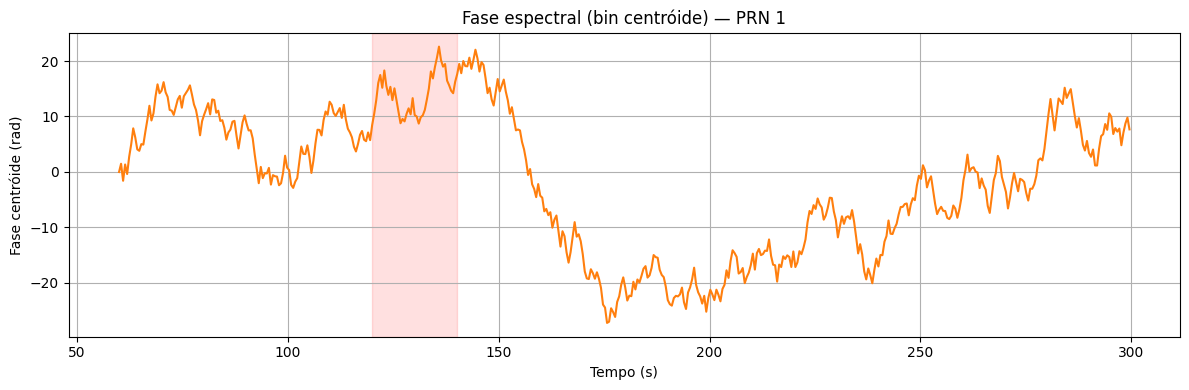

Slope pré (rad/s): -0.06874552433641712
Slope pós (rad/s): 0.051290269984080795
Δ slope (rad/s): 0.12003579432049791


In [110]:
# Fase espectral (bin centróide) — PRN 1
# Esta célula substitui a anterior (FFT magnitude/fase) para mostrar apenas
# a evolução temporal da fase do bin correspondente ao centróide espectral
# após despreading do PRN 1.
# Passos:
# 1. Definimos PRN_SELECT = 1 e geramos o código (se função ca_code já existir).
# 2. Subamostramos os tempos para reduzir custo (step).
# 3. Para cada tempo: lemos janela, aplicamos despreading, calculamos FFT com Hann,
#    estimamos o centróide em ±1 MHz e pegamos o bin mais próximo.
# 4. Registramos fase (unwrap) e centralizamos removendo o valor inicial.
# 5. Plotamos apenas fase vs tempo.

# Garantir PRN 1 ativo
try:
    PRN_SELECT = 1
    code = ca_code(PRN_SELECT)  # função definida em célula anterior
    # Vetor de código expandido a amostras do sinal para despreading direto:
    # Tentamos reutilizar despread_window já existente; se não existir, criamos simples.
    if 'despread_window' not in globals():
        def despread_window(x: np.ndarray) -> np.ndarray:
            # Ajusta código para tamanho da janela (repetição)
            N = len(x)
            chips = code.astype(np.float32)
            # Upsample simples por repetição para cobrir N (assumindo ~1.023 Mcps vs 25 Msps: fator ~24.4)
            reps = int(np.ceil(N / len(chips)))
            ca_up = np.tile(chips, reps)[:N]
            return x * ca_up
except Exception as e:
    print('Falha ao preparar PRN 1:', e)

step = 20  # menor step -> maior resolução (mais FFTs)
T_sub = T[::step]
N_sub = len(T_sub)

phase = np.empty(N_sub, dtype=np.float64)
fc_series = np.empty(N_sub, dtype=np.float64)

w_local = np.hanning(win_N).astype(np.float32)
freqs_full = fftshift(fftfreq(win_N, d=1/fs))
mask_centroid = np.abs(freqs_full) <= 1_000_000.0

for i, t in enumerate(T_sub):
    x = read_window_at_time(float(t), win_N)
    x_d = despread_window(x)
    X_d = fftshift(fft(x_d * w_local))
    P = (np.abs(X_d)**2)[mask_centroid]
    F = freqs_full[mask_centroid]
    denom = np.sum(P) + 1e-30
    fc = np.sum(F * P) / denom
    fc_series[i] = fc
    idx = np.argmin(np.abs(freqs_full - fc))
    phase[i] = np.angle(X_d[idx])

# Unwrap e centralização
phase_u = np.unwrap(phase)
phase_center = phase_u - phase_u[0]

fig, ax = plt.subplots(1,1, figsize=(12,4))
ax.plot(T_sub, phase_center, color='C1')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('Fase centróide (rad)')
ax.set_title('Fase espectral (bin centróide) — PRN 1')
ax.axvspan(120,140, color='r', alpha=0.12)
ax.grid(True)
plt.tight_layout(); plt.show()

# Métrica simples de inclinação média pré vs pós (rad/s)
pre_mask = T_sub < 120
post_mask = T_sub > 140
if np.any(pre_mask) and np.any(post_mask):
    # Converter fase em função do tempo para slope aproximado
    def slope(tvec, ph):
        if tvec.size < 2: return np.nan
        tm = np.mean(tvec); pm = np.mean(ph)
        denom = np.sum((tvec - tm)**2) + 1e-30
        b = np.sum((tvec - tm)*(ph - pm)) / denom
        return b  # rad/s
    slope_pre = slope(T_sub[pre_mask], phase_center[pre_mask])
    slope_post = slope(T_sub[post_mask], phase_center[post_mask])
    print('Slope pré (rad/s):', slope_pre)
    print('Slope pós (rad/s):', slope_post)
    print('Δ slope (rad/s):', slope_post - slope_pre)
else:
    print('Intervalos pré/pós insuficientes para slopes.')